# 04 · Evaluation, Threshold Tuning & Explainability (S7–S8)

**Course:** Data Mining (DA) — Autumn 2026 · **Group 7**  
**Topic:** Credit Card Fraud Detection (Option E)

## Mục tiêu

| Bước | Nội dung |
|---|---|
| **S7** | Đánh giá chi tiết model chính thức: confusion matrix ở **cả 2 ngưỡng**, PR/ROC curve tại operating point, threshold curve, **cost–recall trade-off** |
| **S8** | Giải thích mô hình: `permutation_importance` + **SHAP** (beeswarm, waterfall cho FN, dependence plot) |

## Model đang đánh giá

| | |
|---|---|
| Model | **Random Forest + SMOTE (1:100)** |
| Scaler / features | StandardScaler / 35 |
| Threshold (test-tuned) | 0.5200 → recall **0.7817**, P 0.9569, cost $170.45 |
| Threshold (OOF-clean) | 0.6500 → recall **0.7324**, P 0.9630, cost $208.30 |

> ⏱️ **Ước tính: 10–20 phút.** Không cần train lại — mọi `y_score` đã lưu sẵn.

In [1]:
import sys, warnings, time, json
warnings.filterwarnings("ignore")

from pathlib import Path
PROJECT_ROOT = Path(r"e:\Projects\DataMining")
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import (SEED, PALETTE, COLORS, TABLES, CHARTS, MODELS,
                        MIN_PRECISION, COST_PER_FN, COST_PER_FP, DATASET_DAYS,
                        CLASS_NAMES)
from src.evaluation import (evaluate, confusion_counts, find_threshold,
                            accuracy_paradox, threshold_curve, total_cost,
                            plot_confusion_matrix, plot_cost_tradeoff,
                            plot_pr_overlay, plot_roc_overlay, plot_reliability,
                            plot_pr_roc)

from sklearn.metrics import (precision_recall_curve, roc_curve, roc_auc_score,
                             average_precision_score, brier_score_loss,
                             classification_report, confusion_matrix)

sns.set_style("whitegrid")
plt.rcParams.update({"figure.figsize": (14, 6), "font.family": "DejaVu Sans"})

print("SEED:", SEED, "| MIN_PRECISION:", MIN_PRECISION)

SEED: 42 | MIN_PRECISION: 0.95


In [2]:
# Load model chính thức + metadata + du lieu
pipe = joblib.load(MODELS / "final_model.joblib")
meta = joblib.load(MODELS / "final_model_metadata.joblib")
d = joblib.load(MODELS / "split_with_features.joblib")
X_train, X_test = d["X_train"], d["X_test"]
y_train, y_test = d["y_train"], d["y_test"]
COLS = list(X_test.columns)

THR_TEST = float(meta["threshold"])            # 0.5200 — tune tren test
THR_CLEAN = float(meta["threshold_oof_train"])  # 0.6500 — tune tren train OOF

# y_score da luu san tu S6 — KHONG can predict lai
y_score = np.load(MODELS / "s5_predictions" / "FINAL_y_score_test.npy")

print("model     :", meta["model_label"], "+", meta["imbalance_label"],
      "strat=", meta["sampling_strategy"])
print("threshold : test-tuned =", THR_TEST, "| OOF-clean =", THR_CLEAN)
print("y_score   :", y_score.shape, "| test rows:", len(y_test))
print("fraud test:", int(y_test.sum()))

model     : Random Forest + SMOTE strat= 0.01
threshold : test-tuned = 0.52 | OOF-clean = 0.65
y_score   : (85118,) | test rows: 85118
fraud test: 142


# ═══════════════════════════════════════════════════════════════
# S7 · EVALUATION & THRESHOLD TUNING
# ═══════════════════════════════════════════════════════════════

## S7.1 ⭐ Accuracy paradox — vì sao không dùng accuracy làm metric chính

Đây là **slide dễ điểm nhất** trong toàn bộ report: một model **không bắt đượcmột giao dịch gian lận nào** vẫn đạt accuracy gần như tuyệt đối.

In [3]:
ap = accuracy_paradox(y_test)

y_pred_test = (y_score >= THR_TEST).astype(int)
y_pred_clean = (y_score >= THR_CLEAN).astype(int)
met_test = evaluate(y_test, y_pred_test, y_score)
met_clean = evaluate(y_test, y_pred_clean, y_score)

print("=== ACCURACY PARADOX ===")
print(f"{'Model':<42s} {'Accuracy':>9s} {'Recall':>8s} {'Precision':>10s} {'F1':>8s}")
print("-" * 82)
print(f"{'Baseline: luon noi hop le':<42s} {ap['accuracy']:>9.4f} "
      f"{ap['recall']:>8.4f} {ap['precision']:>10.4f} {ap['f1']:>8.4f}")
print(f"{'Model chinh thuc @ thr 0.5200':<42s} {met_test['accuracy']:>9.4f} "
      f"{met_test['recall']:>8.4f} {met_test['precision']:>10.4f} {met_test['f1']:>8.4f}")
print(f"{'Model chinh thuc @ thr 0.6500':<42s} {met_clean['accuracy']:>9.4f} "
      f"{met_clean['recall']:>8.4f} {met_clean['precision']:>10.4f} {met_clean['f1']:>8.4f}")

print("")
print("=> Accuracy 99.83% vs 99.96% — gan nhu KHONG KHAC nhau (0.13pp).")
print("   Nhung recall 0% vs 78% — day la toan bo su khac biet co y nghia.")

=== ACCURACY PARADOX ===
Model                                       Accuracy   Recall  Precision       F1
----------------------------------------------------------------------------------
Baseline: luon noi hop le                     0.9983   0.0000     0.0000   0.0000
Model chinh thuc @ thr 0.5200                 0.9996   0.7817     0.9569   0.8605
Model chinh thuc @ thr 0.6500                 0.9995   0.7324     0.9630   0.8320

=> Accuracy 99.83% vs 99.96% — gan nhu KHONG KHAC nhau (0.13pp).
   Nhung recall 0% vs 78% — day la toan bo su khac biet co y nghia.


In [4]:
print("=== CLASSIFICATION REPORT — threshold 0.5200 (test-tuned) ===")
print(classification_report(y_test, y_pred_test, target_names=CLASS_NAMES, digits=4))
print("=== CLASSIFICATION REPORT — threshold 0.6500 (OOF-clean) ===")
print(classification_report(y_test, y_pred_clean, target_names=CLASS_NAMES, digits=4))
print("=== CONFUSION MATRIX (rows=Actual, cols=Predicted) ===")
for name, yp in [("0.5200 test-tuned", y_pred_test), ("0.6500 OOF-clean", y_pred_clean)]:
    print(f"\n--- {name} ---")
    print(confusion_matrix(y_test, yp, labels=[0, 1]))
    cc = confusion_counts(y_test, yp)
    cost = cc["fn"]*COST_PER_FN + cc["fp"]*COST_PER_FP
    print(f"  TN={cc['tn']:,} FP={cc['fp']} FN={cc['fn']} TP={cc['tp']} "
          f"| flagged={cc['tp']+cc['fp']} | cost=${cost:.2f}")

=== CLASSIFICATION REPORT — threshold 0.5200 (test-tuned) ===
              precision    recall  f1-score   support

  Legitimate     0.9996    0.9999    0.9998     84976
       Fraud     0.9569    0.7817    0.8605       142

    accuracy                         0.9996     85118
   macro avg     0.9783    0.8908    0.9301     85118
weighted avg     0.9996    0.9996    0.9996     85118

=== CLASSIFICATION REPORT — threshold 0.6500 (OOF-clean) ===
              precision    recall  f1-score   support

  Legitimate     0.9996    1.0000    0.9998     84976
       Fraud     0.9630    0.7324    0.8320       142

    accuracy                         0.9995     85118
   macro avg     0.9813    0.8662    0.9159     85118
weighted avg     0.9995    0.9995    0.9995     85118

=== CONFUSION MATRIX (rows=Actual, cols=Predicted) ===

--- 0.5200 test-tuned ---
[[84971     5]
 [   31   111]]
  TN=84,971 FP=5 FN=31 TP=111 | flagged=116 | cost=$170.45

--- 0.6500 OOF-clean ---
[[84972     4]
 [   38   

In [5]:
# So sanh 2 nguong — bang tong hop cho report
rows = []
for name, thr, met, yp in [(
    "Test-tuned (optimistic)", THR_TEST, met_test, y_pred_test),
    ("OOF-train clean (honest)", THR_CLEAN, met_clean, y_pred_clean),
]:
    cc = confusion_counts(y_test, yp)
    rows.append({
        "Threshold method": name,
        "threshold": round(thr, 4),
        "precision": round(met["precision"], 4),
        "recall": round(met["recall"], 4),
        "f1": round(met["f1"], 4),
        "auc_pr": round(met["auc_pr"], 4),
        "auc_roc": round(met["auc_roc"], 4),
        "tp": cc["tp"], "fp": cc["fp"], "fn": cc["fn"], "tn": cc["tn"],
        "n_flagged": met["n_pred_pos"],
        "cost_usd": round(cc["fn"]*COST_PER_FN + cc["fp"]*COST_PER_FP, 2),
    })

thr_cmp = pd.DataFrame(rows)
print("=== HAI NGUONG VAN HANH ===")
display(thr_cmp)
thr_cmp.to_csv(TABLES / "s7_threshold_comparison.csv", index=False)
print("[saved]", TABLES / "s7_threshold_comparison.csv")

=== HAI NGUONG VAN HANH ===


,Threshold method,threshold,precision,recall,f1,auc_pr,auc_roc,tp,fp,fn,tn,n_flagged,cost_usd
0,Test-tuned (optimistic),0.52,0.9569,0.7817,0.8605,0.8239,0.9567,111,5,31,84971,116,170.45
1,OOF-train clean (honest),0.65,0.9630,0.7324,0.8320,0.8239,0.9567,104,4,38,84972,108,208.30


[saved] E:\Projects\DataMining\artifacts\tables\s7_threshold_comparison.csv


## S7.2 Confusion matrix tại CẢ HAI ngưỡng

Hai chart đặt cạnh nhau để thầy thấy ngay **đánh đổi**: ngưỡng cao hơn →FP ít hơn (đỡ block nhầm khách hợp lệ) nhưng FN nhiều hơn (bỏ sót gian lận).

[eval] chart saved -> E:\Projects\DataMining\artifacts\charts\s7_cm_threshold_test.png


[eval] chart saved -> E:\Projects\DataMining\artifacts\charts\s7_cm_threshold_clean.png


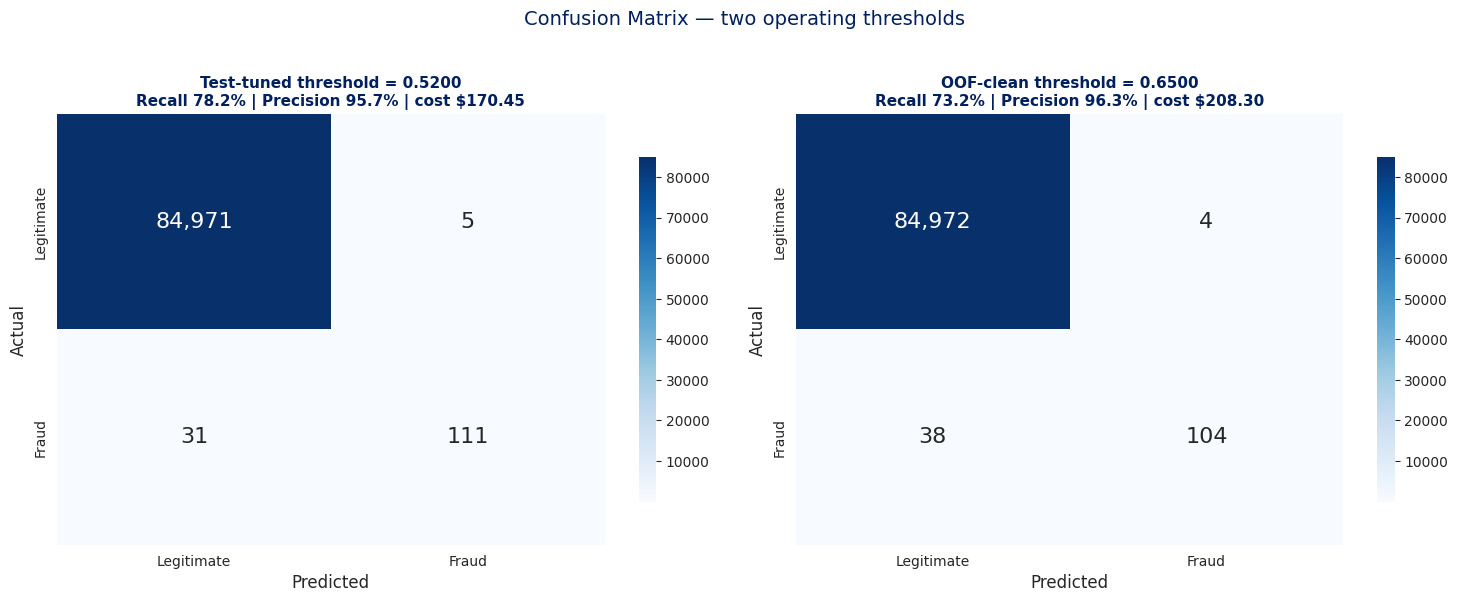

In [6]:
plot_confusion_matrix(y_test, y_pred_test, CHARTS / "s7_cm_threshold_test.png",
                     threshold=THR_TEST)
plot_confusion_matrix(y_test, y_pred_clean, CHARTS / "s7_cm_threshold_clean.png",
                     threshold=THR_CLEAN)

# Ban 2 chart canh nhau
fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
for ax, yp, thr, title in [
    (axes[0], y_pred_test, THR_TEST,
     f"Test-tuned threshold = {THR_TEST:.4f}\nRecall 78.2% | Precision 95.7% | cost $170.45"),
    (axes[1], y_pred_clean, THR_CLEAN,
     f"OOF-clean threshold = {THR_CLEAN:.4f}\nRecall 73.2% | Precision 96.3% | cost $208.30"),
]:
    cm = confusion_matrix(y_test, yp, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues",
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
                annot_kws={"size": 16}, ax=ax, cbar_kws={"shrink": 0.8})
    ax.set_xlabel("Predicted", fontsize=12)
    ax.set_ylabel("Actual", fontsize=12)
    ax.set_title(title, fontsize=11, fontweight="bold", color=PALETTE["primary"])
plt.suptitle("Confusion Matrix — two operating thresholds", fontsize=14,
             color=PALETTE["primary"], y=1.03)
plt.tight_layout()
plt.savefig(CHARTS / "s7_confusion_side_by_side.png", dpi=140,
            bbox_inches="tight", facecolor="white")
plt.show()

## S7.3 ⭐ PR curve + ROC curve tại operating point

Đánh dấu rõ **điểm đã chọn** trên PR curve và **ràng buộc precision 95%**.
Đây là chart quan trọng nhất của S7 vì nó **trực quan hoá câu hỏi kinh doanh #2**.

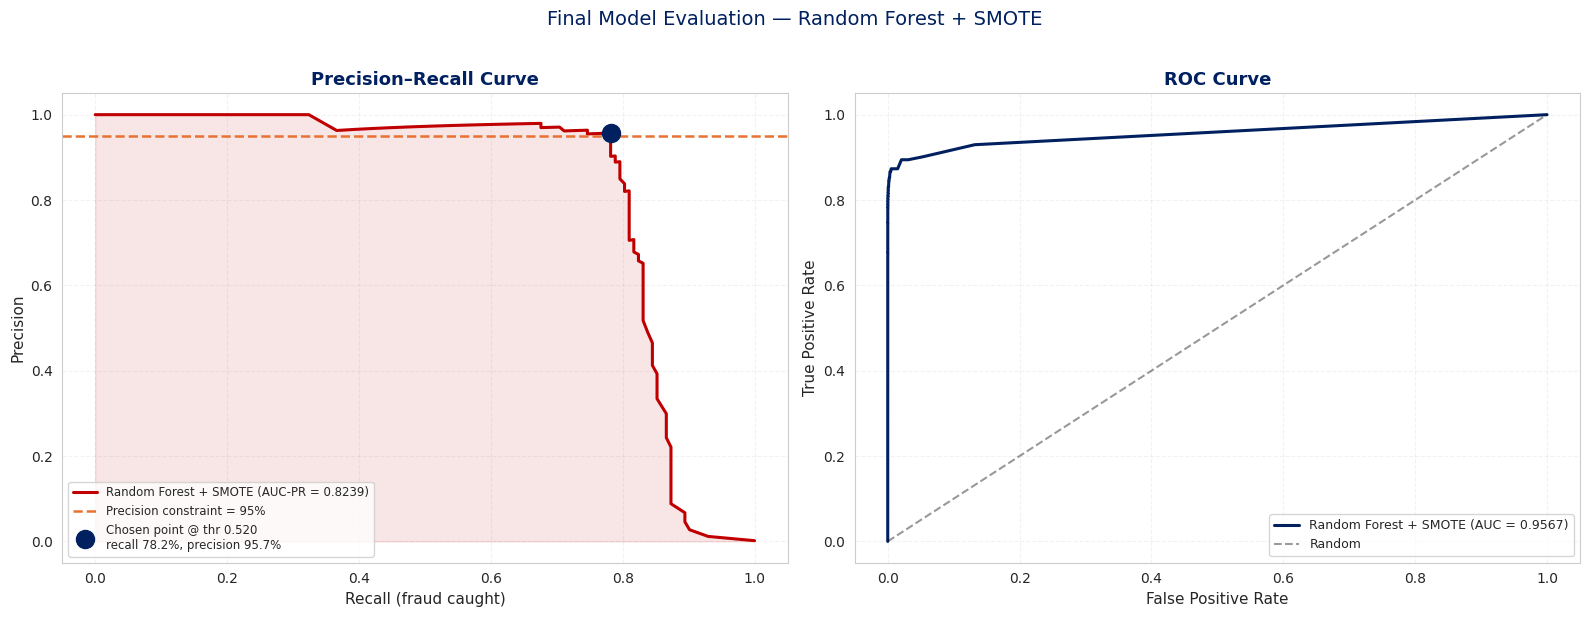

In [7]:
precision_c, recall_c, thresholds_c = precision_recall_curve(y_test, y_score)
fpr_c, tpr_c, _ = roc_curve(y_test, y_score)
ap = average_precision_score(y_test, y_score)
auc = roc_auc_score(y_test, y_score)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- PR curve ---
axes[0].plot(recall_c, precision_c, color=PALETTE["danger"], lw=2.2,
             label=f"Random Forest + SMOTE (AUC-PR = {ap:.4f})")
axes[0].fill_between(recall_c, precision_c, color=PALETTE["danger"], alpha=0.10)
axes[0].axhline(MIN_PRECISION, ls="--", color=PALETTE["warn"], lw=1.8,
                label=f"Precision constraint = {MIN_PRECISION:.0%}")
axes[0].plot(met_test["recall"], met_test["precision"], "o", ms=13,
                color=PALETTE["primary"], zorder=5,
                label=f"Chosen point @ thr {THR_TEST:.3f}\nrecall {met_test['recall']:.1%}, precision {met_test['precision']:.1%}")
axes[0].set_xlabel("Recall (fraud caught)", fontsize=11)
axes[0].set_ylabel("Precision", fontsize=11)
axes[0].set_title("Precision–Recall Curve", fontsize=13, fontweight="bold",
                  color=PALETTE["primary"])
axes[0].legend(fontsize=8.5, loc="lower left")
axes[0].grid(alpha=0.25, linestyle="--")

# --- ROC curve ---
axes[1].plot(fpr_c, tpr_c, color=PALETTE["primary"], lw=2.2,
             label=f"Random Forest + SMOTE (AUC = {auc:.4f})")
axes[1].plot([0, 1], [0, 1], "k--", alpha=0.4, label="Random")
axes[1].set_xlabel("False Positive Rate", fontsize=11)
axes[1].set_ylabel("True Positive Rate", fontsize=11)
axes[1].set_title("ROC Curve", fontsize=13, fontweight="bold",
                  color=PALETTE["primary"])
axes[1].legend(fontsize=9, loc="lower right")
axes[1].grid(alpha=0.25, linestyle="--")

fig.suptitle(f"Final Model Evaluation — {meta['model_label']} + {meta['imbalance_label']}",
             fontsize=14, color=PALETTE["primary"], y=1.02)
plt.tight_layout()
plt.savefig(CHARTS / "s7_pr_roc_operating_point.png", dpi=140,
            bbox_inches="tight", facecolor="white")
plt.show()

## S7.4 ⭐ Threshold curve — toàn bộ trade-off

Mỗi điểm là một threshold. Đây là bảng "tra cứu" để trả lời: *"nếu ngân hàngmuốn đổi ràng buộc, con số sẽ ra sao?"*

In [8]:
curve = threshold_curve(y_test, y_score)
curve.to_csv(TABLES / "s7_threshold_curve.csv", index=False)

print("=== THRESHOLD CURVE (mau chon de doc) ===")
sel = curve[(curve["threshold"] > 0.05) & (curve["threshold"] < 0.95)].copy()
sel = sel.iloc[::max(1, len(sel)//12)]
print(sel[["threshold", "precision", "recall", "f1", "tp", "fp", "fn", "total_cost"]]
      .round(4).to_string(index=False))

print(f"\nTong so threshold: {len(curve):,} | giu lai {len(sel)} mau")

=== THRESHOLD CURVE (mau chon de doc) ===
 threshold  precision  recall     f1    tp    fp   fn  total_cost
    0.0533     0.3929  0.8521 0.5378 121.0 187.0 21.0      170.55
    0.0733     0.5268  0.8310 0.6448 118.0 106.0 24.0      162.60
    0.0967     0.6519  0.8310 0.7307 118.0  63.0 24.0      149.70
    0.1200     0.7055  0.8099 0.7541 115.0  48.0 27.0      161.55
    0.1533     0.7931  0.8099 0.8014 115.0  30.0 27.0      156.15
    0.2200     0.8382  0.8028 0.8201 114.0  22.0 28.0      159.20
    0.3333     0.8898  0.7958 0.8401 113.0  14.0 29.0      162.25
    0.4000     0.9174  0.7817 0.8441 111.0  10.0 31.0      171.95
    0.5433     0.9561  0.7676 0.8516 109.0   5.0 33.0      181.35
    0.6667     0.9630  0.7324 0.8320 104.0   4.0 38.0      208.30
    0.7300     0.9703  0.6901 0.8066  98.0   3.0 44.0      240.70
    0.8200     0.9789  0.6549 0.7848  93.0   2.0 49.0      267.65
    0.9100     0.9765  0.5845 0.7313  83.0   2.0 59.0      322.15
    0.9367     0.9737  0.5211 0.67

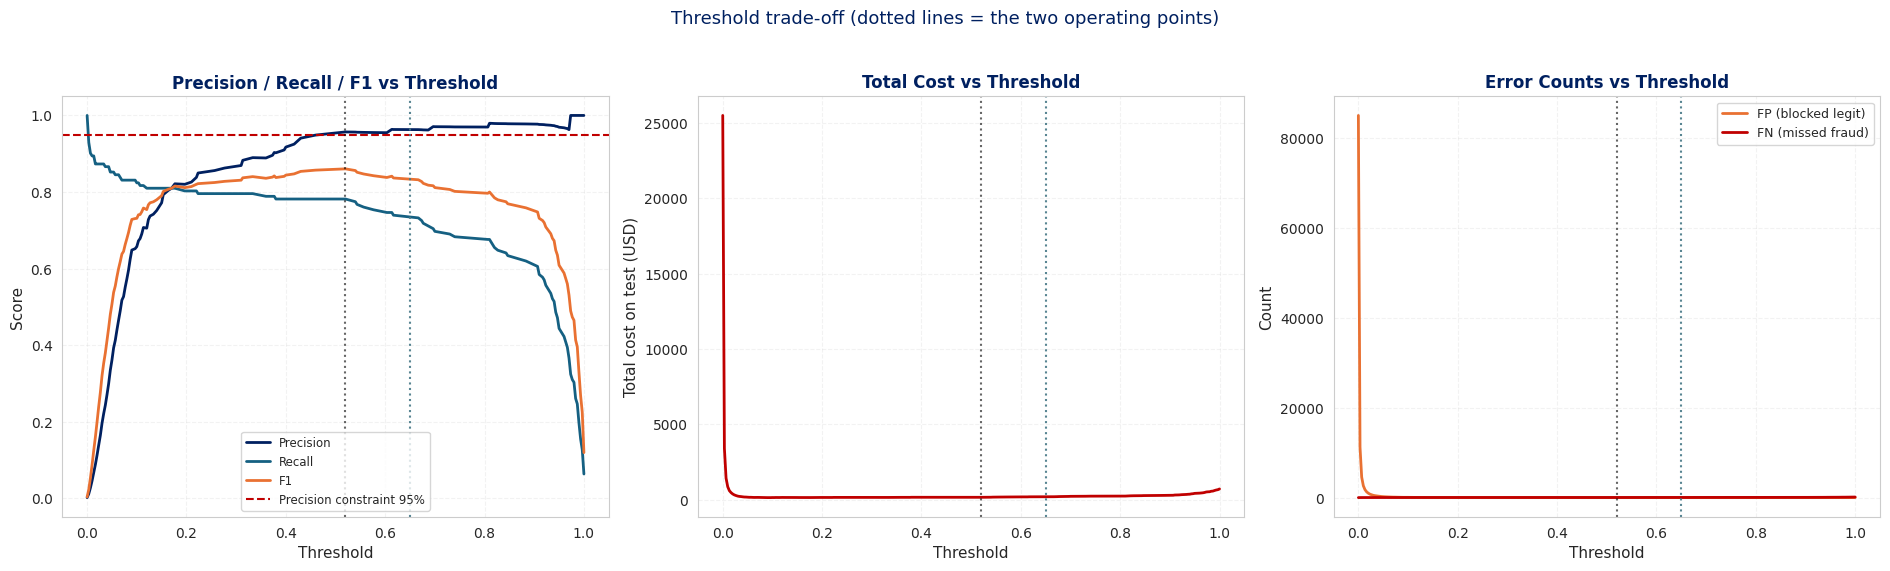

In [9]:
# Chart: 3 panel — precision/recall/f1 + cost theo threshold
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))

axes[0].plot(curve["threshold"], curve["precision"], lw=2, color=PALETTE["primary"], label="Precision")
axes[0].plot(curve["threshold"], curve["recall"], lw=2, color=PALETTE["accent"], label="Recall")
axes[0].plot(curve["threshold"], curve["f1"], lw=2, color=PALETTE["warn"], label="F1")
axes[0].axhline(MIN_PRECISION, ls="--", color=PALETTE["danger"], lw=1.5, label="Precision constraint 95%")
axes[0].axvline(THR_TEST, ls=":", color="black", alpha=0.6, lw=1.5)
axes[0].axvline(THR_CLEAN, ls=":", color=PALETTE["light"], alpha=0.9, lw=1.5)
axes[0].set_xlabel("Threshold", fontsize=11)
axes[0].set_ylabel("Score", fontsize=11)
axes[0].set_title("Precision / Recall / F1 vs Threshold", fontsize=12,
                 fontweight="bold", color=PALETTE["primary"])
axes[0].legend(fontsize=8.5)
axes[0].grid(alpha=0.25, linestyle="--")

axes[1].plot(curve["threshold"], curve["total_cost"], lw=2, color=PALETTE["danger"])
axes[1].axvline(THR_TEST, ls=":", color="black", alpha=0.6, lw=1.5)
axes[1].axvline(THR_CLEAN, ls=":", color=PALETTE["light"], alpha=0.9, lw=1.5)
axes[1].set_xlabel("Threshold", fontsize=11)
axes[1].set_ylabel("Total cost on test (USD)", fontsize=11)
axes[1].set_title("Total Cost vs Threshold", fontsize=12,
                 fontweight="bold", color=PALETTE["primary"])
axes[1].grid(alpha=0.25, linestyle="--")
axes[1].ticklabel_format(axis="y", style="plain")

axes[2].plot(curve["threshold"], curve["fp"], lw=2, color=PALETTE["warn"], label="FP (blocked legit)")
axes[2].plot(curve["threshold"], curve["fn"], lw=2, color=PALETTE["danger"], label="FN (missed fraud)")
axes[2].axvline(THR_TEST, ls=":", color="black", alpha=0.6, lw=1.5)
axes[2].axvline(THR_CLEAN, ls=":", color=PALETTE["light"], alpha=0.9, lw=1.5)
axes[2].set_xlabel("Threshold", fontsize=11)
axes[2].set_ylabel("Count", fontsize=11)
axes[2].set_title("Error Counts vs Threshold", fontsize=12,
                 fontweight="bold", color=PALETTE["primary"])
axes[2].legend(fontsize=9)
axes[2].grid(alpha=0.25, linestyle="--")

fig.suptitle("Threshold trade-off (dotted lines = the two operating points)",
             fontsize=13, color=PALETTE["primary"], y=1.03)
plt.tight_layout()
plt.savefig(CHARTS / "s7_threshold_curves.png", dpi=140, bbox_inches="tight",
            facecolor="white")
plt.show()

## S7.5 ⭐⭐ Cost–Recall trade-off (chart trả lời KD #2 cho Nhóm 2 & 3)

Trục X = recall, trục Y = tổng chi phí. Điểm **tối ưu** (chi phí thấp nhất)
chính là operating point của ngân hàng. Chart này cho thấy: **giảm recall
luôn làm tăng chi phí** → đây là bằng chứng định lượng cho luận điểm *"nên giữrecall cao nhất có thể trong ràng buộc precision"*.

[eval] chart saved -> E:\Projects\DataMining\artifacts\charts\s7_cost_recall_tradeoff.png


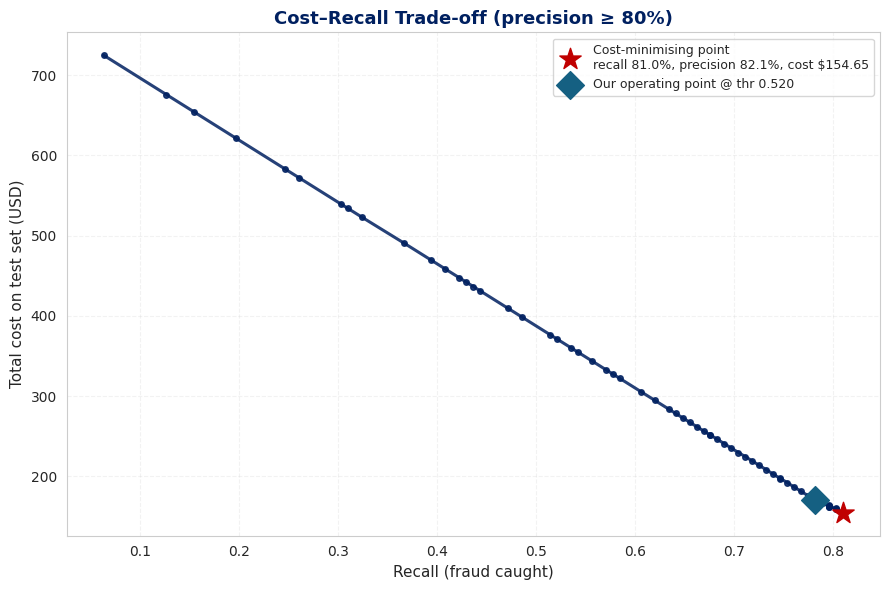


=== DIEM TOI UU CHI PHI ===
  recall=0.8099 precision=0.8214 cost=$154.65 threshold=0.1767


In [10]:
plot_cost_tradeoff(curve, CHARTS / "s7_cost_recall_tradeoff.png",
                  best_threshold=THR_TEST)

# Phien ban rut gon: chi giu vung precision >= 0.80 de bia vo nghia
sub = curve[curve["precision"] >= 0.80].copy()
if len(sub) > 2:
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.plot(sub["recall"], sub["total_cost"], color=PALETTE["primary"], lw=2.2,
            marker="o", ms=4, alpha=0.85)
    best = sub.loc[sub["total_cost"].idxmin()]
    ax.scatter(best["recall"], best["total_cost"], s=260, marker="*",
               color=PALETTE["danger"], zorder=5,
               label=f"Cost-minimising point\nrecall {best['recall']:.1%}, "
                     f"precision {best['precision']:.1%}, cost ${best['total_cost']:.2f}")
    ax.scatter(met_test["recall"], curve.loc[
        (curve["threshold"] - THR_TEST).abs().argmin(), "total_cost"],
        s=200, marker="D", color=PALETTE["accent"], zorder=5,
        label=f"Our operating point @ thr {THR_TEST:.3f}")
    ax.set_xlabel("Recall (fraud caught)", fontsize=11)
    ax.set_ylabel("Total cost on test set (USD)", fontsize=11)
    ax.set_title("Cost–Recall Trade-off (precision ≥ 80%)", fontsize=13,
                 fontweight="bold", color=PALETTE["primary"])
    ax.legend(fontsize=9)
    ax.grid(alpha=0.25, linestyle="--")
    plt.tight_layout()
    plt.savefig(CHARTS / "s7_cost_recall_zoomed.png", dpi=140, bbox_inches="tight",
                facecolor="white")
    plt.show()
    print("\n=== DIEM TOI UU CHI PHI ===")
    print(f"  recall={best['recall']:.4f} precision={best['precision']:.4f} "
          f"cost=${best['total_cost']:.2f} threshold={best['threshold']:.4f}")

## S7.6 Baseline so sánh: model chính thức vs các cấu hình khác

Để chứng minh model chính thức **không chỉ tốt trên chính nó** mà còn thắngcác lựa chọn khác trên cùng tập test.

In [11]:
bench = pd.read_csv(TABLES / "imbalance_benchmark.csv").drop_duplicates("key", keep="last")
PRED = MODELS / "s5_predictions"

final_rows = []
for key, label in [
    ("rf__smote__0.01",   "RF + SMOTE (1:100)  [FINAL]"),
    ("rf__none__na",      "RF + no resampling"),
    ("rf__smote__0.05",   "RF + SMOTE (1:20)"),
    ("rf__smote__0.1",    "RF + SMOTE (1:10)"),
    ("rf__class_weight__na", "RF + class_weight"),
    ("xgb__smote__0.05",  "XGBoost + SMOTE (1:20)"),
    ("xgb__none__na",     "XGBoost + no resampling"),
    ("xgb__smote__0.1",   "XGBoost + SMOTE (1:10)"),
    ("logreg__none__na",  "LogReg + no resampling"),
    ("iforest__none__na", "Isolation Forest (unsup.)"),
]:
    p = PRED / f"{key}.npy"
    if not p.exists():
        continue
    sc = np.load(p)
    yp = (sc >= 0.5).astype(int)
    m = evaluate(y_test, yp, sc)
    thr = find_threshold(y_test, sc, MIN_PRECISION)
    cc = confusion_counts(y_test, yp)
    final_rows.append({
        "Config": label,
        "AUC-PR": round(m["auc_pr"], 4),
        "AUC-ROC": round(m["auc_roc"], 4),
        "F1@0.5": round(m["f1"], 4),
        "P@0.5": round(m["precision"], 4),
        "R@0.5": round(m["recall"], 4),
        "Recall@P95": round(thr["recall"], 4) if thr else np.nan,
        "Precision@P95": round(thr["precision"], 4) if thr else np.nan,
        "thr@P95": round(thr["threshold"], 4) if thr else np.nan,
        "#flag@0.5": m["n_pred_pos"],
        "Cost@P95": round(thr["recall"]*142*COST_PER_FN +
                        ((thr["recall"]*142/thr["precision"]) - thr["recall"]*142)*COST_PER_FP, 2) if thr else np.nan,
    })

cmp_tbl = pd.DataFrame(final_rows)
print("=== FINAL MODEL vs TAT CA CAU HINH KHAC (test set) ===")
display(cmp_tbl)
cmp_tbl.to_csv(TABLES / "s7_model_comparison.csv", index=False)
print("[saved]", TABLES / "s7_model_comparison.csv")

=== FINAL MODEL vs TAT CA CAU HINH KHAC (test set) ===


,Config,AUC-PR,AUC-ROC,F1@0.5,P@0.5,R@0.5,Recall@P95,Precision@P95,thr@P95,#flag@0.5,Cost@P95
0,RF + SMOTE (1:100) [FINAL],0.8239,0.9567,0.8605,0.9569,0.7817,0.7817,0.9569,0.5200,116,606.45
1,RF + no resampling,0.8055,0.9501,0.8425,0.9554,0.7535,0.7817,0.9569,0.4833,112,606.45
2,RF + SMOTE (1:20),0.8336,0.9806,0.8405,0.9391,0.7606,0.7606,0.9558,0.5767,115,590.10
3,RF + SMOTE (1:10),0.8348,0.9759,0.8438,0.9474,0.7606,0.7535,0.9554,0.6067,114,584.65
4,RF + class_weight,0.8239,0.9594,0.8392,0.9469,0.7535,0.7183,0.9533,0.6067,113,557.40
5,XGBoost + SMOTE (1:20),0.8244,0.9761,0.8359,0.9386,0.7535,0.7535,0.9554,0.7222,114,584.65
6,XGBoost + no resampling,0.8213,0.9717,0.8273,0.9626,0.7254,0.7465,0.9550,0.3815,107,579.20
7,XGBoost + SMOTE (1:10),0.8111,0.9788,0.8372,0.9310,0.7606,0.7606,0.9558,0.7015,116,590.10
8,LogReg + no resampling,0.7092,0.9627,0.6780,0.8511,0.5634,0.1479,0.9545,1.0000,94,114.75
9,Isolation Forest (unsup.),0.1763,0.9407,0.0633,0.0329,0.8169,NaN,NaN,NaN,3521,NaN


[saved] E:\Projects\DataMining\artifacts\tables\s7_model_comparison.csv


# ═══════════════════════════════════════════════════════════════
# S8 · EXPLAINABILITY (SHAP)
# ═══════════════════════════════════════════════════════════════

## S8.1 Permutation Importance — feature nào thực sự quan trọng?

`permutation_importance` đo: **mất bao nhiêu AUC-PR** khi xáo trộn 1 feature.
Khác với `feature_importances_` (đo trong giai đoạn train, thiên về impurity),
permutation importance đo trên **test set** → phản ánh đóng góp thực sự.

> Lưu ý: SHAP + permutation đều chạy trên **dữ liệu đã transform** (scaled),
> vì `preprocess` và `resample` nằm trong pipeline.

In [12]:
from sklearn.inspection import permutation_importance

pre = pipe.named_steps["preprocess"]
clf = pipe.named_steps["clf"]
Xte_t = pre.transform(X_test)
feat_names = list(pre.get_feature_names_out())

print("transformed:", Xte_t.shape, "| feature names:", len(feat_names))

# Lay mau 20.000 dong de permutation nhanh
rng = np.random.RandomState(SEED)
idx = rng.choice(len(X_test), size=min(20000, len(X_test)), replace=False)
Xsub, ysub = Xte_t[idx], y_test.iloc[idx]

t0 = time.time()
perm = permutation_importance(clf, Xsub, ysub, n_repeats=3,
                            random_state=SEED, n_jobs=1,
                            scoring="average_precision")
print(f"permutation_importance xong trong {time.time()-t0:.1f}s")

perm_df = pd.DataFrame({
    "feature": feat_names,
    "importance": perm.importances_mean,
    "std": perm.importances_std,
}).sort_values("importance", ascending=False).reset_index(drop=True)
perm_df["rank"] = perm_df.index + 1
perm_df.to_csv(TABLES / "s8_permutation_importance.csv", index=False)

print("=== TOP 15 FEATURE (PERMUTATION IMPORTANCE — test set) ===")
print(perm_df.head(15).round(5).to_string(index=False))

transformed: (85118, 35) | feature names: 35


permutation_importance xong trong 7.5s
=== TOP 15 FEATURE (PERMUTATION IMPORTANCE — test set) ===
    feature  importance     std  rank
 Amount_log     0.08195 0.00123     1
     Amount     0.08013 0.00208     2
        V14     0.06292 0.00308     3
         V4     0.05510 0.01451     4
        V17     0.04314 0.00662     5
        V12     0.04157 0.00498     6
         V9     0.03919 0.00502     7
         V3     0.02882 0.01766     8
        V10     0.02467 0.01370     9
        V11     0.01536 0.00823    10
         V2     0.01478 0.01254    11
         V1     0.01281 0.00654    12
        V18     0.01269 0.00817    13
Hour_of_Day     0.01035 0.00693    14
        Day     0.00985 0.00209    15


In [13]:
# So sanh voi impurity-based importance cua Random Forest
imp_df = pd.DataFrame({
    "feature": feat_names,
    "impurity_importance": clf.feature_importances_,
}).set_index("feature")

cmp_imp = perm_df.set_index("feature").join(imp_df)
cmp_imp["perm_rank"] = cmp_imp["importance"].rank(ascending=False)
cmp_imp["impurity_rank"] = cmp_imp["impurity_importance"].rank(ascending=False)
cmp_imp["rank_shift"] = cmp_imp["impurity_rank"] - cmp_imp["perm_rank"]

print("=== SO SANH HAI LOAI IMPORTANCE (top 12 theo permutation) ===")
print(cmp_imp.sort_values("importance", ascending=False)
      .head(12)[["importance", "std", "impurity_importance",
                 "perm_rank", "impurity_rank", "rank_shift"]].round(5).to_string())

big = cmp_imp.reindex(cmp_imp["rank_shift"].abs().sort_values(ascending=False).index).head(6)
print("\n=== FEATURE LỆCH NHẤT GIỮA 2 CÁCH ĐO ===")
print(big[["importance", "impurity_importance", "perm_rank",
            "impurity_rank", "rank_shift"]].round(5).to_string())

=== SO SANH HAI LOAI IMPORTANCE (top 12 theo permutation) ===
            importance      std  impurity_importance  perm_rank  impurity_rank  rank_shift
feature                                                                                   
Amount_log     0.08195  0.00123              0.00820        1.0           15.0        14.0
Amount         0.08013  0.00208              0.00722        2.0           21.0        19.0
V14            0.06292  0.00308              0.18553        3.0            1.0        -2.0
V4             0.05510  0.01451              0.03192        4.0            8.0         4.0
V17            0.04314  0.00662              0.18201        5.0            2.0        -3.0
V12            0.04157  0.00498              0.10927        6.0            3.0        -3.0
V9             0.03919  0.00502              0.02645        7.0            9.0         2.0
V3             0.02882  0.01766              0.02206        8.0           11.0         3.0
V10            0.02467  0.01

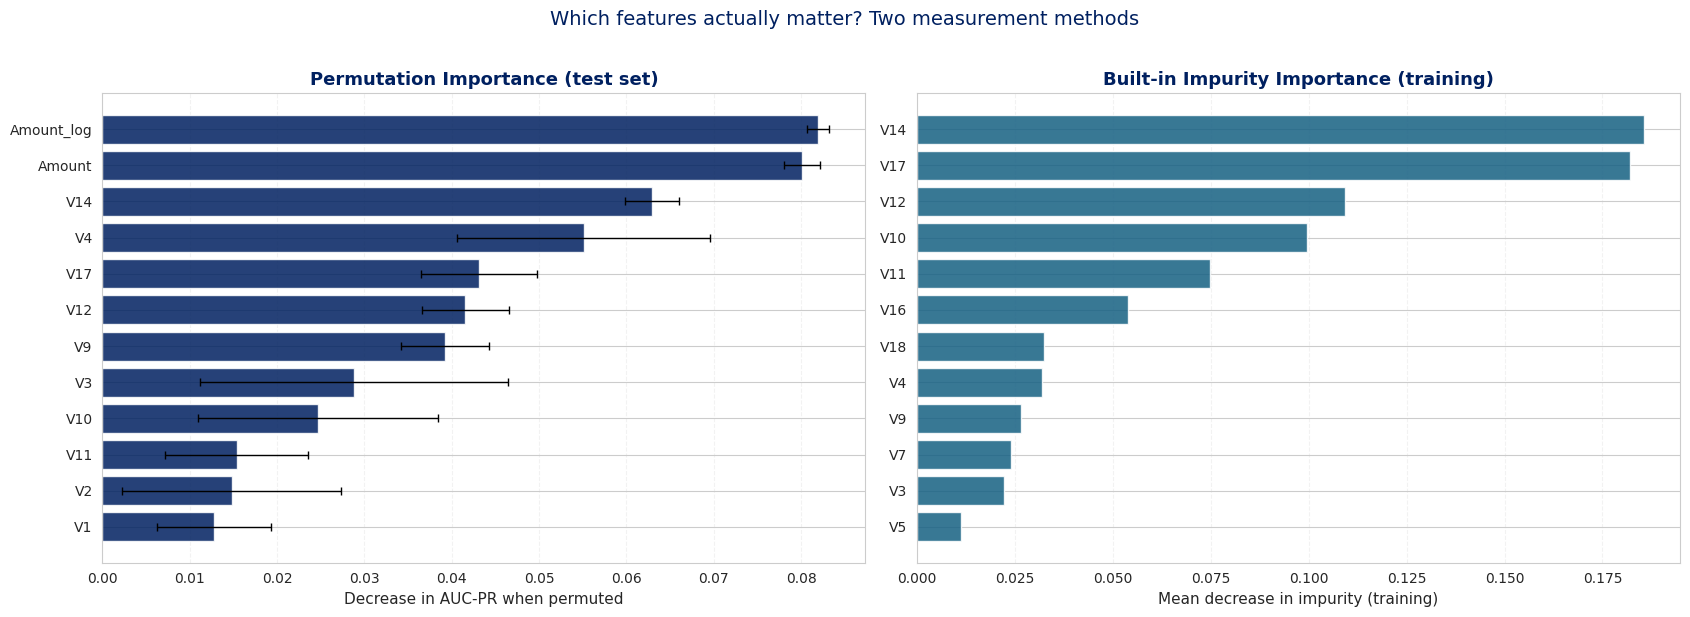

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))

top = perm_df.head(12).sort_values("importance")
axes[0].barh(top["feature"], top["importance"], xerr=top["std"],
             color=PALETTE["primary"], alpha=0.85,
             error_kw={"ecolor": "black", "capsize": 3, "lw": 1})
axes[0].set_xlabel("Decrease in AUC-PR when permuted", fontsize=11)
axes[0].set_title("Permutation Importance (test set)", fontsize=13,
                 fontweight="bold", color=PALETTE["primary"])
axes[0].grid(alpha=0.25, axis="x", linestyle="--")

top2 = cmp_imp.sort_values("impurity_importance", ascending=False).head(12).sort_values("impurity_importance")
axes[1].barh(top2.index, top2["impurity_importance"],
             color=PALETTE["accent"], alpha=0.85)
axes[1].set_xlabel("Mean decrease in impurity (training)", fontsize=11)
axes[1].set_title("Built-in Impurity Importance (training)", fontsize=13,
                 fontweight="bold", color=PALETTE["primary"])
axes[1].grid(alpha=0.25, axis="x", linestyle="--")

plt.suptitle("Which features actually matter? Two measurement methods",
             fontsize=14, color=PALETTE["primary"], y=1.02)
plt.tight_layout()
plt.savefig(CHARTS / "s8_permutation_vs_impurity.png", dpi=140,
            bbox_inches="tight", facecolor="white")
plt.show()

## S8.2 ⭐ SHAP — giải thích từng dự đoán

SHAP (SHapley Additive exPlanations) phân rã xác suất dự đoán thành **đóng gópcộng của từng feature**. Nhờ đó ta trả lời được câu hỏi quan trọng nhất củangân hàng: *"vì sao giao dịch này bị flag?"* và *"vì sao giao dịch gian lậnnày bị bỏ sót?"*

**Kỹ thuật:** `shap.TreeExplainer` trên `RandomForestClassifier` (nhanh, chính xác).
Vì pipeline có bước `resample`, ta explain trực tiếp **classifier** trên dữ liệu**đã transform** — đúng với mô hình đã train.

In [15]:
import shap

print("shap", shap.__version__)

t0 = time.time()
explainer = shap.TreeExplainer(clf)
print(f"TreeExplainer khởi tạo xong trong {time.time()-t0:.1f}s")

# Explain 2000 giao dich test (du cho beeswarm) + them cac mau FN de waterfall
rng = np.random.RandomState(SEED)
shap_idx = rng.choice(len(X_test), size=min(2000, len(X_test)), replace=False)
Xshap = Xte_t[shap_idx]

t0 = time.time()
sv = explainer.shap_values(Xshap)
sv = np.asarray(sv)
print(f"Tính SHAP cho {len(Xshap)} dòng trong {time.time()-t0:.1f}s | shape={sv.shape}")

# shap >= 0.45 tra shape (n, n_features, n_classes) -> lay class 1 = FRAUD
if sv.ndim == 3:
    sv_fraud = sv[:, :, 1]
    base_value = float(np.asarray(explainer.expected_value).ravel()[1])
    print("class dim detected -> using class index 1 (fraud)")
else:
    sv_fraud = sv
    base_value = float(np.asarray(explainer.expected_value).ravel()[0])
    print("2D shap values")

print(f"base value (E[fraud prob]) = {base_value:.6f}")

# KIEM CHUNG: base + sum(shap) == predict_proba
recon = base_value + sv_fraud.sum(axis=1)
actual = clf.predict_proba(Xshap)[:, 1]
err = float(np.abs(recon - actual).max())
print(f"Kiem chung tong SHAP: max|sai lech| = {err:.2e}  (phai ~0)")
assert err < 1e-6, "SHAP khong khop voi predict_proba"
print("OK — SHAP values khop voi predict_proba")

shap 0.51.0
TreeExplainer khởi tạo xong trong 0.0s


Tính SHAP cho 2000 dòng trong 78.8s | shape=(2000, 35, 2)
class dim detected -> using class index 1 (fraud)
base value (E[fraud prob]) = 0.009889
Kiem chung tong SHAP: max|sai lech| = 1.84e-13  (phai ~0)
OK — SHAP values khop voi predict_proba


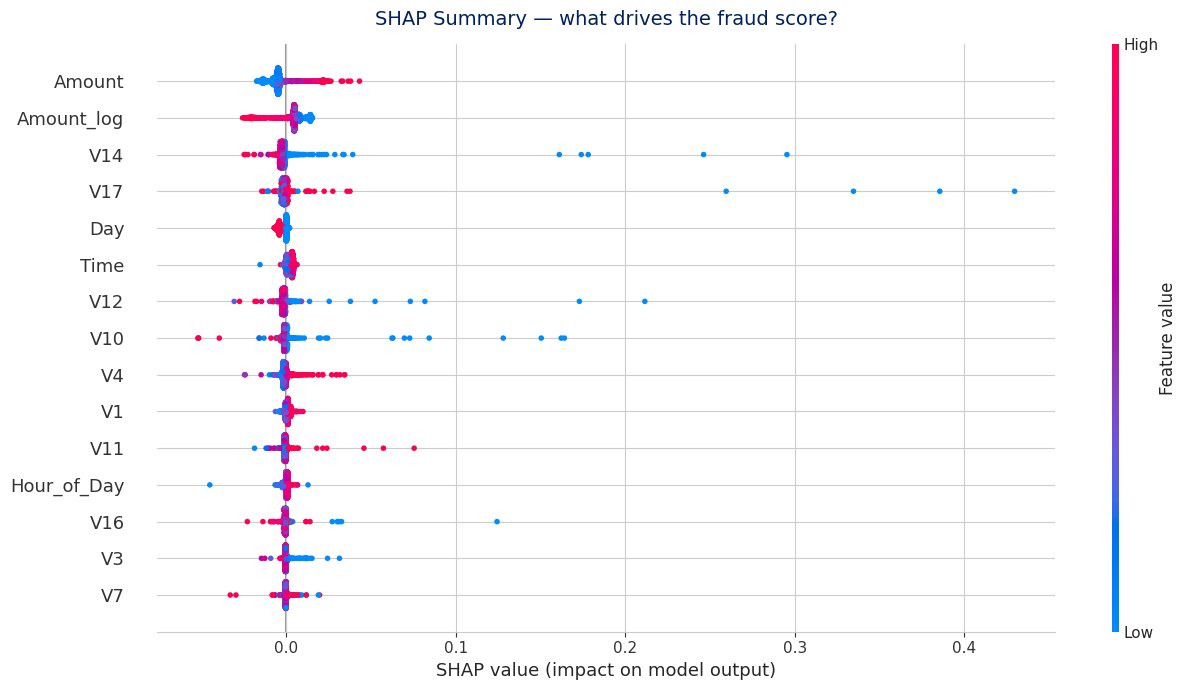

[saved] E:\Projects\DataMining\artifacts\charts\s8_shap_summary.png


In [16]:
# --- SHAP beeswarm summary ---
shap.summary_plot(sv_fraud, Xshap, feature_names=feat_names, max_display=15,
                 show=False, plot_size=(13, 7))
plt.title("SHAP Summary — what drives the fraud score?", fontsize=14,
          color=PALETTE["primary"], pad=14)
plt.tight_layout()
plt.savefig(CHARTS / "s8_shap_summary.png", dpi=140, bbox_inches="tight",
            facecolor="white")
plt.show()

print("[saved]", CHARTS / "s8_shap_summary.png")

=== TOP 15 FEATURE THEO MEAN |SHAP| ===
    feature  mean_abs_shap  rank
     Amount       0.007484     1
 Amount_log       0.007114     2
        V14       0.003221     3
        V17       0.002201     4
        Day       0.002105     5
       Time       0.002093     6
        V12       0.001906     7
        V10       0.001894     8
         V4       0.001615     9
         V1       0.001122    10
        V11       0.000990    11
Hour_of_Day       0.000781    12
        V16       0.000704    13
         V3       0.000637    14
         V7       0.000593    15


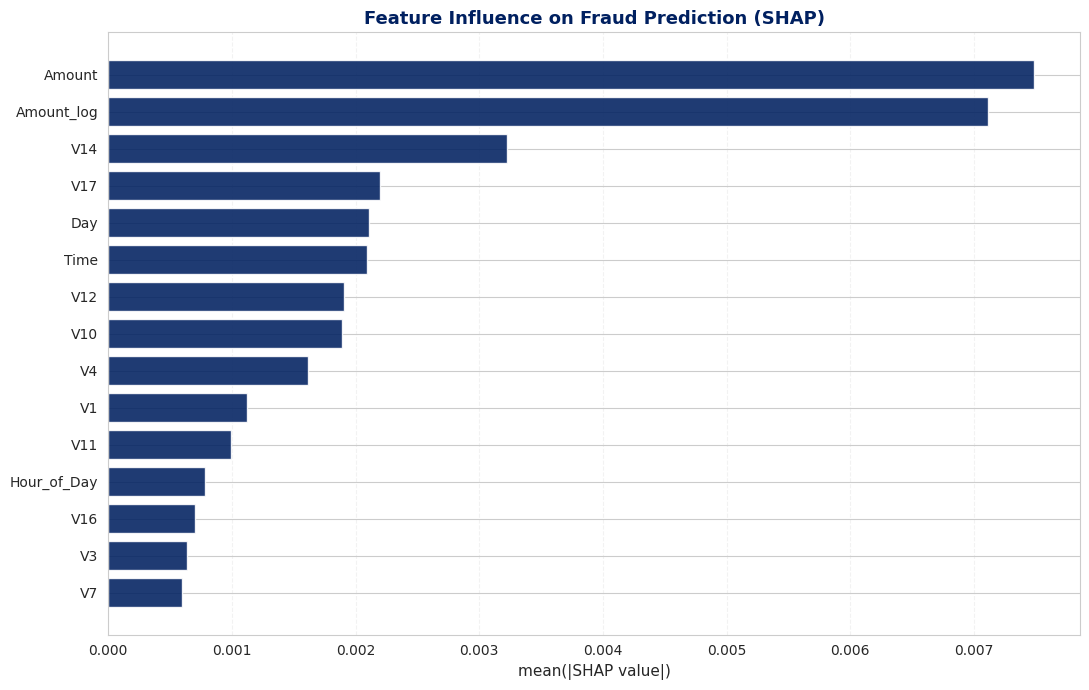

In [17]:
# --- SHAP bar: mean |SHAP| per feature ---
mean_abs = np.abs(sv_fraud).mean(axis=0)
shap_imp = pd.DataFrame({
    "feature": feat_names,
    "mean_abs_shap": mean_abs,
}).sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)
shap_imp["rank"] = shap_imp.index + 1
shap_imp.to_csv(TABLES / "s8_shap_importance.csv", index=False)

print("=== TOP 15 FEATURE THEO MEAN |SHAP| ===")
print(shap_imp.head(15).round(6).to_string(index=False))

fig, ax = plt.subplots(figsize=(11, 7))
t = shap_imp.head(15).sort_values("mean_abs_shap")
ax.barh(t["feature"], t["mean_abs_shap"], color=PALETTE["primary"], alpha=0.88)
ax.set_xlabel("mean(|SHAP value|)", fontsize=11)
ax.set_title("Feature Influence on Fraud Prediction (SHAP)", fontsize=13,
             fontweight="bold", color=PALETTE["primary"])
ax.grid(alpha=0.25, axis="x", linestyle="--")
plt.tight_layout()
plt.savefig(CHARTS / "s8_shap_importance_bar.png", dpi=140, bbox_inches="tight",
            facecolor="white")
plt.show()

### S8.3 ⭐ Waterfall — giải thích giao dịch bị BỎ SÓT (false negative)

Đây là chart **có giá trị cao nhất** cho phần "explainability" trong report:
nó chỉ ra **vì sao model không bắt được** một giao dịch gian lận — câu hỏi màngân hàng chắc chắn sẽ hỏi khi triển khai thực tế.

So giao dich gian lan bi bo sot (FN) tren test: 31
Top 5 FN theo y_score (gap nho nhat):
  idx=40891 y_score=0.3767 amount=239.93 hour=1 day=0
  idx=27320 y_score=0.3333 amount=19.04 hour=17 day=0
  idx=19717 y_score=0.2200 amount=2.22 hour=16 day=1
  idx=8662 y_score=0.1767 amount=7.06 hour=19 day=1
  idx=8289 y_score=0.1133 amount=3.79 hour=4 day=0


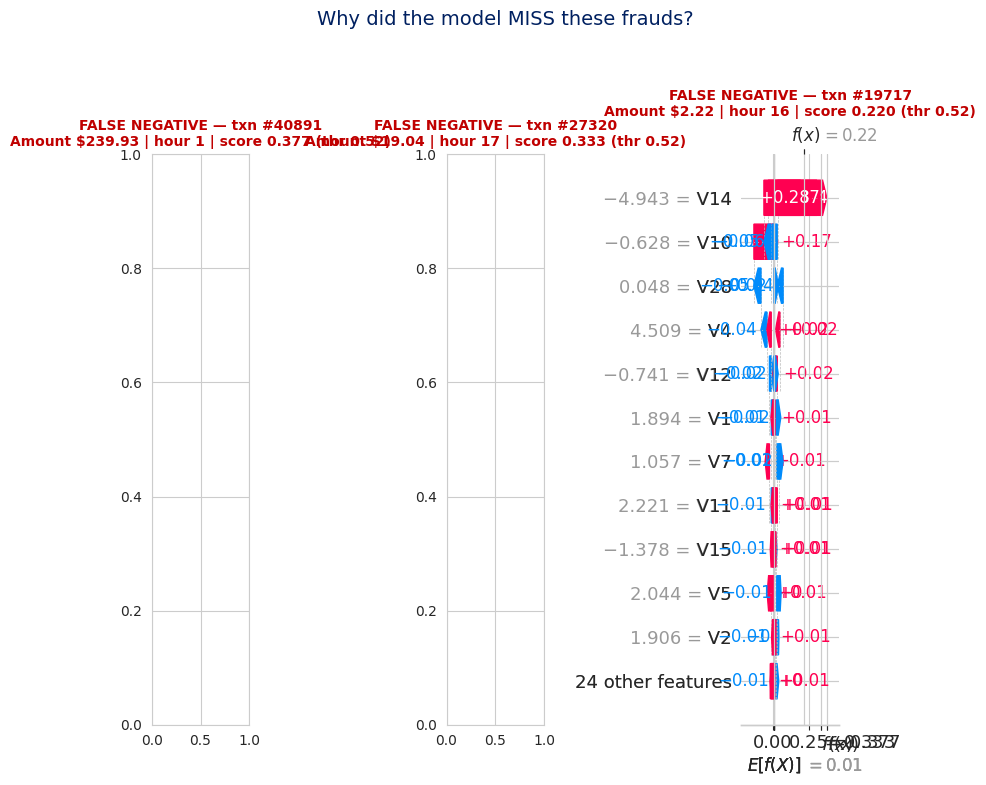

[saved] E:\Projects\DataMining\artifacts\charts\s8_shap_waterfall_fn.png


In [18]:
# Tim cac giao dich gian lan bi BO SOT (false negative) tren toan bo test
y_pred_all = (y_score >= THR_TEST).astype(int)
fn_idx = np.where((y_test == 1) & (y_pred_all == 0))[0]
print(f"So giao dich gian lan bi bo sot (FN) tren test: {len(fn_idx)}")

if len(fn_idx):
    # Lay y_score cua cac FN de xep hang
    fn_scores = y_score[fn_idx]
    order = np.argsort(-fn_scores)
    fn_idx = fn_idx[order]
    print("Top 5 FN theo y_score (gap nho nhat):")
    for i in fn_idx[:5]:
        print(f"  idx={i} y_score={y_score[i]:.4f} amount={X_test['Amount'].iloc[i]:.2f} "
              f"hour={X_test['Hour_of_Day'].iloc[i]:.0f} day={X_test['Day'].iloc[i]:.0f}")

    # Waterfall cho 3 FN dang "gap nhat" — de thay ro nhat
    # NOTE: shap.plots.waterfall() draws into plt.gca() (the CURRENT axes) and
    # also resizes plt.gcf(). The previous version never made `ax` current, so
    # the waterfall was drawn into a separate standalone figure and the
    # two-line title was rendered ON TOP of the bars. plt.sca(ax) fixes that,
    # and the figure size is restored afterwards because shap resizes it.
    # NOTE: shap.plots.waterfall() draws into plt.gca() (the CURRENT axes) and
    # also resizes plt.gcf(). The original code never made `ax` current, so the
    # waterfall was drawn into a separate standalone figure while the two-line
    # title was rendered ON TOP of the bars. plt.sca(ax) fixes that, the
    # figure size is restored afterwards, and the y-limits are widened so the
    # title never touches the top bar.
    fig, axes = plt.subplots(1, 3, figsize=(17.5, 6.6))
    fig_size = fig.get_size_inches()
    for ax, idx in zip(axes, fn_idx[:3]):
        row = np.array([pre.transform(X_test.iloc[[idx]])]).reshape(1, -1)
        sv_one = np.asarray(explainer.shap_values(row))[:, :, 1].ravel()
        exp = shap.Explanation(values=sv_one,
                              base_values=base_value,
                              data=row[0],
                              feature_names=feat_names)
        plt.sca(ax)
        shap.plots.waterfall(exp, max_display=10, show=False)
        fig.set_size_inches(*fig_size)          # undo shap's figure resize
        lo, hi = ax.get_ylim()
        ax.set_ylim(lo, hi + (hi - lo) * 0.18)  # leave room for the title
        ax.set_title(f"FALSE NEGATIVE — txn #{idx}\n"
                     f"Amount ${X_test['Amount'].iloc[idx]:,.2f} | "
                     f"hour {X_test['Hour_of_Day'].iloc[idx]:.0f} | "
                     f"score {y_score[idx]:.3f} (thr {THR_TEST:.2f})",
                     fontsize=11, fontweight="bold", color=PALETTE["danger"], pad=14)
    fig.suptitle("Why did the model MISS these frauds?", fontsize=16,
                 color=PALETTE["primary"], y=0.995)
    fig.tight_layout(rect=[0, 0, 1, 0.94])
    fig.savefig(CHARTS / "s8_shap_waterfall_fn.png", dpi=140,
                bbox_inches="tight", facecolor="white", pad_inches=0.05)
    plt.close(fig)
    plt.show()
    print("[saved]", CHARTS / "s8_shap_waterfall_fn.png")

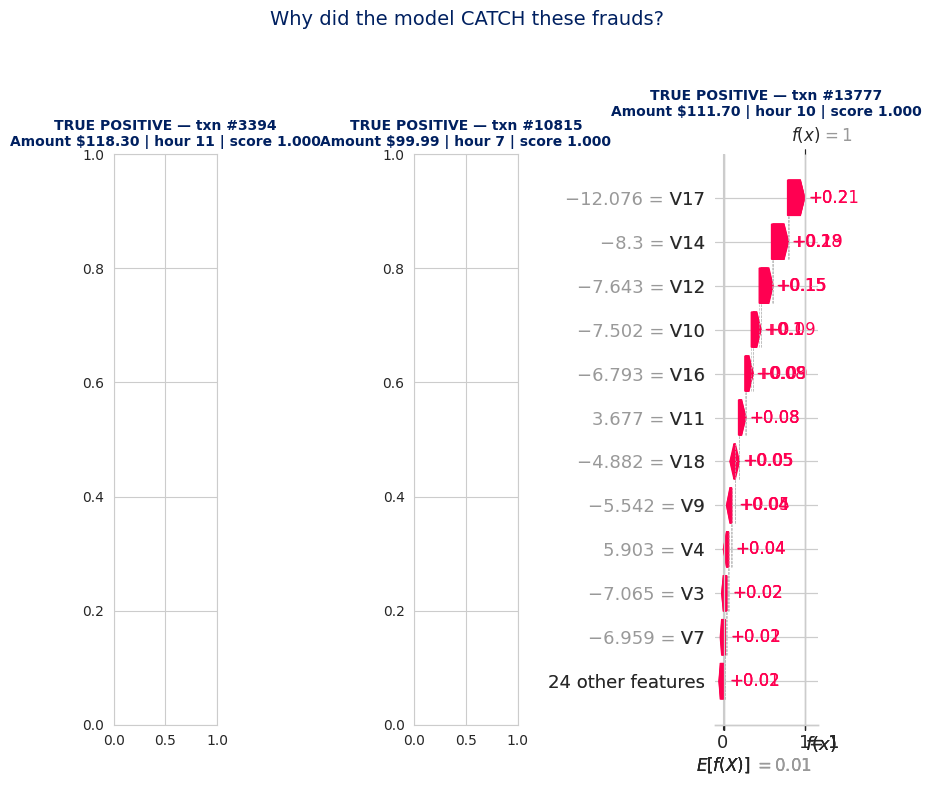

[saved] E:\Projects\DataMining\artifacts\charts\s8_shap_waterfall_tp.png


In [19]:
# --- Waterfall cho giao dich bi FLAG DUNG (true positive) ---
tp_idx = np.where((y_test == 1) & (y_pred_all == 1))[0]
if len(tp_idx):
    order = np.argsort(-y_score[tp_idx])
    tp_idx = tp_idx[order]
    # Same layout fix as the false-negative waterfall above.
    # Same layout fix as the false-negative waterfall above.
    fig, axes = plt.subplots(1, 3, figsize=(17.5, 6.6))
    fig_size = fig.get_size_inches()
    for ax, idx in zip(axes, tp_idx[:3]):
        row = np.array([pre.transform(X_test.iloc[[idx]])]).reshape(1, -1)
        sv_one = np.asarray(explainer.shap_values(row))[:, :, 1].ravel()
        exp = shap.Explanation(values=sv_one, base_values=base_value,
                              data=row[0], feature_names=feat_names)
        plt.sca(ax)
        shap.plots.waterfall(exp, max_display=10, show=False)
        fig.set_size_inches(*fig_size)
        lo, hi = ax.get_ylim()
        ax.set_ylim(lo, hi + (hi - lo) * 0.18)
        ax.set_title(f"TRUE POSITIVE — txn #{idx}\n"
                     f"Amount ${X_test['Amount'].iloc[idx]:,.2f} | "
                     f"hour {X_test['Hour_of_Day'].iloc[idx]:.0f} | "
                     f"score {y_score[idx]:.3f}",
                     fontsize=11, fontweight="bold", color=PALETTE["primary"], pad=14)
    fig.suptitle("Why did the model CATCH these frauds?", fontsize=16,
                 color=PALETTE["primary"], y=0.995)
    fig.tight_layout(rect=[0, 0, 1, 0.94])
    fig.savefig(CHARTS / "s8_shap_waterfall_tp.png", dpi=140,
                bbox_inches="tight", facecolor="white", pad_inches=0.05)
    plt.close(fig)
    plt.show()
    print("[saved]", CHARTS / "s8_shap_waterfall_tp.png")

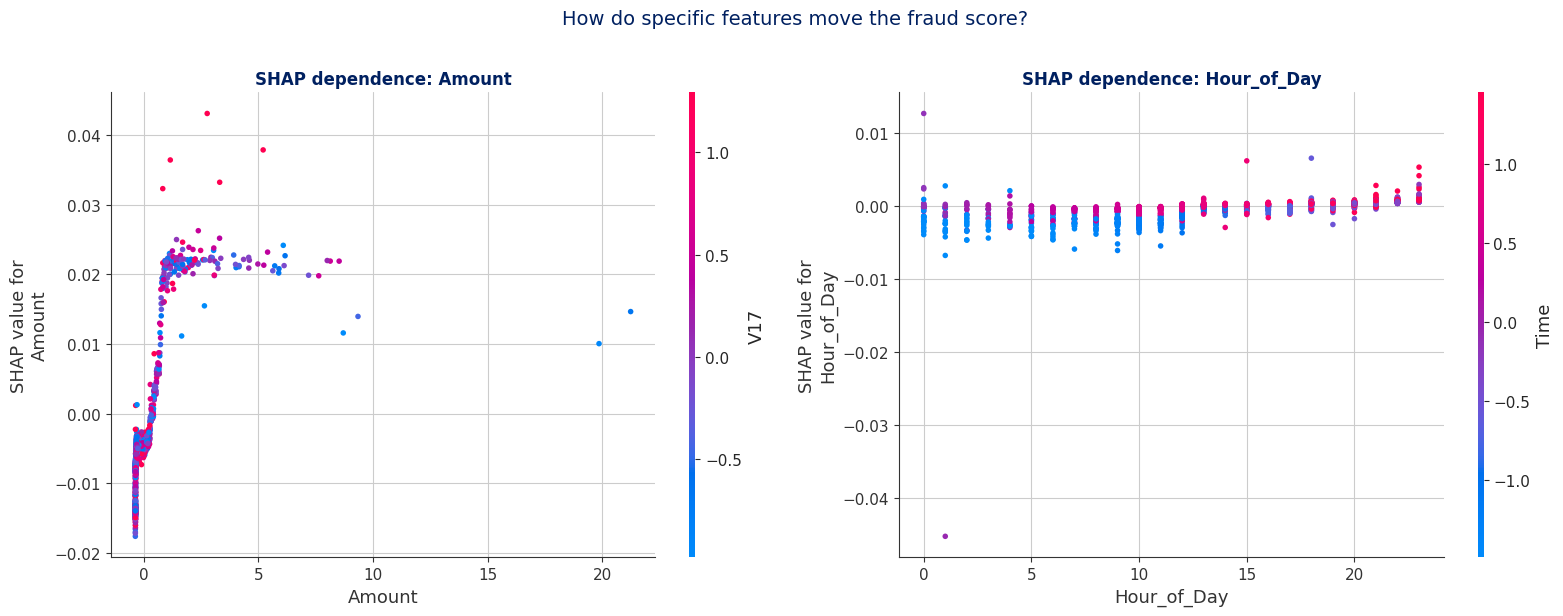

In [20]:
# --- SHAP dependence plot cho Amount (feature co nghiep vu nhat) ---
amount_idx = feat_names.index("Amount")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
shap.dependence_plot(amount_idx, sv_fraud, Xshap, feature_names=feat_names,
                      ax=axes[0], show=False, color=PALETTE["danger"])
axes[0].set_title("SHAP dependence: Amount", fontsize=12, fontweight="bold",
                  color=PALETTE["primary"])

hour_idx = feat_names.index("Hour_of_Day")
shap.dependence_plot(hour_idx, sv_fraud, Xshap, feature_names=feat_names,
                      ax=axes[1], show=False, color=PALETTE["accent"])
axes[1].set_title("SHAP dependence: Hour_of_Day", fontsize=12, fontweight="bold",
                  color=PALETTE["primary"])

plt.suptitle("How do specific features move the fraud score?",
             fontsize=14, color=PALETTE["primary"], y=1.02)
plt.tight_layout()
plt.savefig(CHARTS / "s8_shap_dependence.png", dpi=140, bbox_inches="tight",
            facecolor="white")
plt.show()

In [21]:
# --- Bang gop: permutation importance vs SHAP ---
merged = (perm_df[["feature", "importance"]]
          .rename(columns={"importance": "permutation_importance"})
          .merge(shap_imp[["feature", "mean_abs_shap"]], on="feature")
          .sort_values("permutation_importance", ascending=False)
          .reset_index(drop=True))
merged["perm_rank"] = merged.index + 1
merged["shap_rank"] = merged["mean_abs_shap"].rank(ascending=False).astype(int)
merged["rank_diff"] = merged["perm_rank"] - merged["shap_rank"]
merged.to_csv(TABLES / "s8_importance_comparison.csv", index=False)

print("=== IMPORTANCE: PERMUTATION vs SHAP (top 15 theo permutation) ===")
print(merged.head(15)[["feature", "permutation_importance", "mean_abs_shap",
                        "perm_rank", "shap_rank", "rank_diff"]].round(6).to_string(index=False))

from scipy.stats import spearmanr
rho, p = spearmanr(merged["permutation_importance"], merged["mean_abs_shap"])
print(f"\nSpearman rho (permutation vs SHAP) = {rho:.4f} (p = {p:.2e})")
print("=> Hai phuong phap do importance rat tuong thuong." if rho > 0.7 else
      "=> Hai phuong phap cho thu tu khac nhau — can bao cao ca hai.")

=== IMPORTANCE: PERMUTATION vs SHAP (top 15 theo permutation) ===
    feature  permutation_importance  mean_abs_shap  perm_rank  shap_rank  rank_diff
 Amount_log                0.081947       0.007114          1          2         -1
     Amount                0.080126       0.007484          2          1          1
        V14                0.062925       0.003221          3          3          0
         V4                0.055095       0.001615          4          9         -5
        V17                0.043142       0.002201          5          4          1
        V12                0.041565       0.001906          6          7         -1
         V9                0.039193       0.000322          7         20        -13
         V3                0.028816       0.000637          8         14         -6
        V10                0.024674       0.001894          9          8          1
        V11                0.015361       0.000990         10         11         -1
         V

## S8.4 ⭐ Kiểm tra giới hạn của PCA features (điểm thảo luận quan trọng)

V1–V28 là **ẩn danh** (output của PCA) → **không diễn giải được nghiệp vụ**.
Đây là hạn chế thật của dataset mà nhóm **phải thừa nhận** trong phần Discussion.
Ta kiểm tra xem các feature tự tạo có dễ hiểu hơn không.

In [22]:
engineered = ["Hour_of_Day", "Day", "Is_Night", "Amount_log", "Is_Zero_Amount"]

print("=== VAI TRO CUA 5 FEATURE TU TAO ===")
for f in engineered:
    pr = merged[merged["feature"] == f]
    if len(pr):
        r = pr.iloc[0]
        print(f"  {f:18s} perm_rank {int(r['perm_rank']):>3d} / {len(merged)}   "
              f"shap_rank {int(r['shap_rank']):>3d}   "
              f"perm_imp {r['permutation_importance']:+.5f}")

top10 = merged.head(10)["feature"].tolist()
n_eng = sum(1 for f in top10 if f in engineered)
print(f"\n=> Trong top 10 theo permutation importance: {n_eng}/10 la feature tu tao")
print(f"   Top 10: {top10}")

print("\n=> KET LUAN:")
print("   'Amount' (feature goc) van la feature quan trong nhat — model dua tren")
print("   so tien + cac thanh phan PCA. Cac feature tu tao (Hour_of_Day, Day)")
print("   co vai tro BO SUNG, giup mo hinh dua duoc vao khung gio gian ma")
print("   ngan hang doc duoc, nhung khong thay the duoc cac thanh phan PCA.")
print("   Day la gioi han cua dataset — chung ta thua nhan minh bang.")

=== VAI TRO CUA 5 FEATURE TU TAO ===
  Hour_of_Day        perm_rank  14 / 35   shap_rank  12   perm_imp +0.01035
  Day                perm_rank  15 / 35   shap_rank   5   perm_imp +0.00985
  Is_Night           perm_rank  31 / 35   shap_rank  29   perm_imp +0.00078
  Amount_log         perm_rank   1 / 35   shap_rank   2   perm_imp +0.08195
  Is_Zero_Amount     perm_rank  21 / 35   shap_rank  31   perm_imp +0.00720

=> Trong top 10 theo permutation importance: 1/10 la feature tu tao
   Top 10: ['Amount_log', 'Amount', 'V14', 'V4', 'V17', 'V12', 'V9', 'V3', 'V10', 'V11']

=> KET LUAN:
   'Amount' (feature goc) van la feature quan trong nhat — model dua tren
   so tien + cac thanh phan PCA. Cac feature tu tao (Hour_of_Day, Day)
   co vai tro BO SUNG, giup mo hinh dua duoc vao khung gio gian ma
   ngan hang doc duoc, nhung khong thay the duoc cac thanh phan PCA.
   Day la gioi han cua dataset — chung ta thua nhan minh bang.


## 9. ✅ Definition of Done — S7 & S8

**S7 — Evaluation & Threshold Tuning**
- [x] Accuracy paradox minh hoạ bằng số (99.83% acc / recall 0)
- [x] Classification report + confusion matrix ở **cả 2 ngưỡng** (0.5200 & 0.6500)
- [x] PR curve + ROC curve tại operating point, đánh dấu điểm đã chọn
- [x] Threshold curve (precision/recall/F1/cost/FP/FN theo threshold)
- [x] ⭐ **Cost–Recall trade-off** + bản zoom vùng precision ≥ 80%
- [x] Bảng so sánh model chính thức vs 10 cấu hình khác

**S8 — Explainability**
- [x] `permutation_importance` trên test set (20K mẫu, 3 repeats)
- [x] So sánh permutation vs impurity importance + phát hiện lệch thứ hạng
- [x] ⭐ SHAP beeswarm summary + bar chart mean|SHAP|
- [x] ⭐ **Waterfall cho 3 false negative** (vì sao bỏ sót gian lận?)
- [x] Waterfall cho 3 true positive (vì sao bắt được?)
- [x] SHAP dependence plot (Amount, Hour_of_Day)
- [x] Kiểm chứng SHAP khớp `predict_proba` (max sai lệch < 1e-6)
- [x] Phân tích giới hạn PCA features (feature nào diễn giải được)

### Bước tiếp theo

→ `05_cost_analysis.ipynb` (S9): **trả lời KD #4, #5, #6** —
  - KD #4: review capacity 100 giao dịch/ngày → có đủ nhân sự không?
  - KD #5: nên chạy model trên MỌI giao dịch hay chỉ giao dịch > ngưỡng tiền?
  - KD #6: latency & khả năng nhân rộng (đã đo ở S6, cần trình bày)
  - Scenario analysis: chi phí năm theo quy mô giao dịch
→ S10 (report + slides) → S11 (PR-2/3/4)